In [2]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")

P1 = ("2015-06-01", "2015-06-14")   # training
P2 = ("2015-06-15", "2015-06-21")   # testing

def filter_period(d, start, end):
    s = pd.Timestamp(start)
    e = pd.Timestamp(end) + pd.Timedelta(days=1)
    return d[(d["dt"] >= s) & (d["dt"] < e)]

train = filter_period(df, *P1)
test  = filter_period(df, *P2)

print("Train:", len(train), "event |", train.visitorid.nunique(), "visitor |", train.itemid.nunique(), "item")
print("Test :", len(test),  "event |", test.visitorid.nunique(),  "visitor |", test.itemid.nunique(),  "item")
print(train.event.value_counts())

Train: 278297 event | 148909 visitor | 76420 item
Test : 145976 event | 76996 visitor | 50854 item
event
view           269671
addtocart        6486
transaction      2140
Name: count, dtype: int64


In [3]:
train.drop(columns="dt").to_csv("data/events_train.csv", index=False)
test.drop(columns="dt").to_csv("data/events_test.csv", index=False)
print("Tersimpan")

Tersimpan


In [7]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [8]:
import pandas as pd

driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB)

csv_path = "data/events_train.csv"
batch_size = 5000
total_rows = len(train)
total_chunks = (total_rows // batch_size) + 1

with driver.session(database=DB) as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_path, chunksize=batch_size)
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil")

Mengimpor Batch Data:   0%|          | 0/56 [00:00<?, ?it/s]

Proses impor berhasil


In [9]:
r, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah", database_=DB)
for x in r: print(x["label"], x["jumlah"])

r, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah", database_=DB)
for x in r: print(x["tipe"], x["jumlah"])

['Visitor'] 148909
['Item'] 76420
VIEWED 269671
ADDED_TO_CART 6486
BOUGHT 2140


In [10]:
import numpy as np
from scipy.sparse import csr_matrix

w = {"view": 1, "addtocart": 2, "transaction": 3}
t = train.copy()
t["w"] = t["event"].map(w)
agg = t.groupby(["visitorid", "itemid"])["w"].sum().reset_index()

u_idx = {u: i for i, u in enumerate(agg["visitorid"].unique())}
i_idx = {x: i for i, x in enumerate(agg["itemid"].unique())}
inv_u = {v: k for k, v in u_idx.items()}
inv_i = {v: k for k, v in i_idx.items()}

M = csr_matrix((agg["w"], (agg["visitorid"].map(u_idx), agg["itemid"].map(i_idx))),
               shape=(len(u_idx), len(i_idx)))

def info(name, A):
    n = A.shape[0] * A.shape[1]
    print(f"{name}: shape={A.shape}, nnz={A.nnz}, sparsity={1 - A.nnz/n:.6f}, "
          f"memori={(A.data.nbytes + A.indices.nbytes + A.indptr.nbytes)/1e6:.1f} MB")

info("VSM User (user x item)", M)
info("VSM Item (item x user)", M.T.tocsr())

user_deg = np.diff(M.indptr)              
item_deg = np.diff(M.T.tocsr().indptr)    
print("User: rata2 item/user =", user_deg.mean(), "| median =", np.median(user_deg),
      "| user dgn 1 item =", (user_deg == 1).mean())
print("Item: rata2 user/item =", item_deg.mean(), "| median =", np.median(item_deg),
      "| item dgn 1 user =", (item_deg == 1).mean())

VSM User (user x item): shape=(148909, 76420), nnz=217908, sparsity=0.999981, memori=3.2 MB
VSM Item (item x user): shape=(76420, 148909), nnz=217908, sparsity=0.999981, memori=2.9 MB
User: rata2 item/user = 1.4633635307469663 | median = 1.0 | user dgn 1 item = 0.814564599856288
Item: rata2 user/item = 2.851452499345721 | median = 1.0 | item dgn 1 user = 0.5618555352002094


In [11]:
# pasangan yang akan terbentuk di tiap proyeksi 
pairs_uu = int((item_deg * (item_deg - 1) // 2).sum())   # user-user
pairs_ii = int((user_deg * (user_deg - 1) // 2).sum())   # item-item
print("Batas atas sisi user-user :", pairs_uu, "| simpul:", M.shape[0])
print("Batas atas sisi item-item :", pairs_ii, "| simpul:", M.shape[1])

# simpul terisolasi 
B = M.copy(); B.data[:] = 1
iso_users = int(((B @ (item_deg > 1).astype(int)) == 0).sum())
iso_items = int(((B.T @ (user_deg > 1).astype(int)) == 0).sum())
print(f"User terisolasi: {iso_users} ({iso_users/M.shape[0]:.1%})")
print(f"Item terisolasi: {iso_items} ({iso_items/M.shape[1]:.1%})")

# densitas proyeksi 
dens_uu = pairs_uu / (M.shape[0] * (M.shape[0] - 1) / 2)
dens_ii = pairs_ii / (M.shape[1] * (M.shape[1] - 1) / 2)
print("Densitas user-user:", dens_uu, "| item-item:", dens_ii)
print("Item terpopuler (jumlah user):", item_deg.max(), "| user teraktif (jumlah item):", user_deg.max())

Batas atas sisi user-user : 1714404 | simpul: 148909
Batas atas sisi item-item : 994236 | simpul: 76420
User terisolasi: 29216 (19.6%)
Item terisolasi: 37474 (49.0%)
Densitas user-user: 0.0001546337148285559 | item-item: 0.00034049528022717795
Item terpopuler (jumlah user): 925 | user teraktif (jumlah item): 356


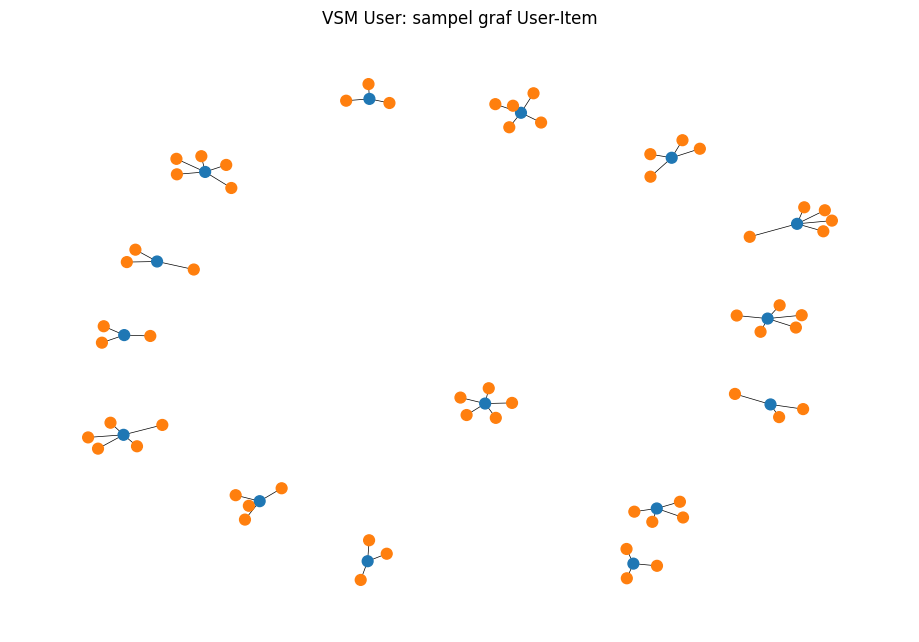

simpul: 75 sisi: 60


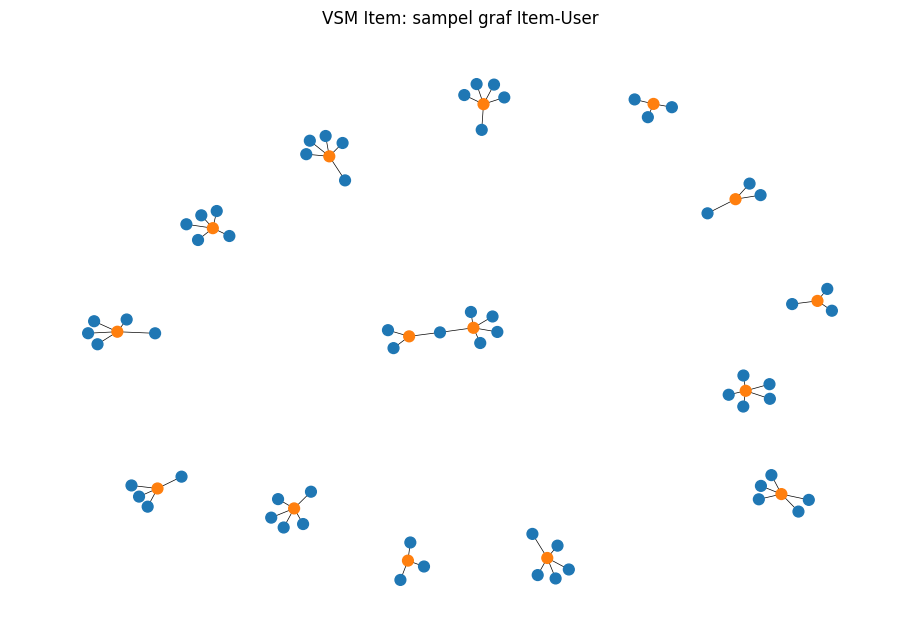

simpul: 78 sisi: 64


In [12]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_sample(A, row_inv, col_inv, rows, title, row_color, col_color):
    G = nx.Graph()
    for r in rows:
        for c in A[r].nonzero()[1][:5]:
            G.add_edge(("r", row_inv[r]), ("c", col_inv[c]))
    colors = [row_color if n[0] == "r" else col_color for n in G.nodes]
    plt.figure(figsize=(9, 6))
    nx.draw_spring(G, node_size=60, node_color=colors, with_labels=False, width=0.5)
    plt.title(title); plt.show()
    print("simpul:", G.number_of_nodes(), "sisi:", G.number_of_edges())

rng = np.random.default_rng(42)
Mt = M.T.tocsr()

# sampel user dengan >= 3 item
sample_users = rng.choice(np.where(user_deg >= 3)[0], size=15, replace=False)
plot_sample(M, inv_u, inv_i, sample_users, "VSM User: sampel graf User-Item", "tab:blue", "tab:orange")

# sampel item dengan >= 3 user
sample_items = rng.choice(np.where(item_deg >= 3)[0], size=15, replace=False)
plot_sample(Mt, inv_i, inv_u, sample_items, "VSM Item: sampel graf Item-User", "tab:orange", "tab:blue")

Selected projection: Items. In terms of efficiency, the items projection has 76,420 nodes (vs. 148,909), an upper bound of 994,236 (vs. 1,714,404, 42% fewer), and a density 2.2 times higher. The user-user projection is dominated by hubs: a single item with 925 users accounts for approximately 427,000 pairs (≈25% of the edges), so many of the edges merely reflect popularity rather than similarity in taste. In terms of effectiveness, the item-item projection does leave 49% of items isolated (vs. 19.6% of users), but those items only.

In [13]:
Bi = M.copy(); Bi.data[:] = 1
item_connected = (Bi.T @ (user_deg > 1).astype(int)) > 0     
user_covered = (Bi @ item_connected.astype(int)) > 0
print(f"User yang bisa dapat rekomendasi item-based: {user_covered.sum()} ({user_covered.mean():.1%})")

User yang bisa dapat rekomendasi item-based: 93747 (63.0%)


In [14]:
def snapshot():
    r, _, _ = driver.execute_query(
        "MATCH ()-[r]->() RETURN type(r) AS tipe, count(*) AS jumlah ORDER BY tipe", database_=DB)
    return {x["tipe"]: x["jumlah"] for x in r}

before = snapshot()
print("SEBELUM:", before)

SEBELUM: {'ADDED_TO_CART': 6486, 'BOUGHT': 2140, 'VIEWED': 269671}


In [15]:
from sklearn.preprocessing import normalize

X  = M.T.tocsr().astype(float)       
Xn = normalize(X)                

ref = int(np.argmax(item_deg))       
ref_id = int(inv_i[ref])
print("Item acuan:", ref_id, "| jumlah user:", item_deg[ref])

sims = (Xn[ref] @ Xn.T).toarray().ravel()    
sims[ref] = -1                             
top = np.argsort(-sims)[:5]

for j in top:
    print(int(inv_i[j]), round(float(sims[j]), 4), "| user:", int(item_deg[j]))

Item acuan: 5411 | jumlah user: 925
33030 0.2348 | user: 55
89143 0.2101 | user: 12
33956 0.1488 | user: 18
459936 0.1427 | user: 15
358234 0.094 | user: 18


In [17]:
rows = [{"a": ref_id, "b": int(inv_i[j]), "s": float(sims[j])} for j in top]
driver.execute_query("""
UNWIND $rows AS r
MATCH (a:Item {itemId: r.a}), (b:Item {itemId: r.b})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = r.s, s.method = 'cosine'
""", rows=rows, database_=DB)

after = snapshot()
print("SESUDAH:", after)

r, _, _ = driver.execute_query("""
MATCH (a:Item {itemId: $id})-[s:SIMILAR]->(b:Item)
RETURN b.itemId AS item, s.score AS score ORDER BY score DESC LIMIT 5
""", id=ref_id, database_=DB)
for x in r: print(x["item"], x["score"])

SESUDAH: {'ADDED_TO_CART': 6486, 'BOUGHT': 2140, 'SIMILAR': 5, 'VIEWED': 269671}
33030 0.2347509182317878
89143 0.21013292020967145
33956 0.1488432607542691
459936 0.14272976241018348
358234 0.09402074024491681
